# Heart Disease Prediction - Part 1 (Clinical data)

Predicts if a patient has heart disease from routine clinical measurements (age, blood pressure, cholesterol, chest pain type, exercise test results...) using the **UCI Heart Disease** dataset.

What is in this notebook:
1. Loading all 4 UCI hospitals (Cleveland, Hungary, Switzerland, VA Long Beach), 920 patients
2. Cleaning: the missing values are hidden as `?` and as `0` (cholesterol = 0 is not possible)
3. EDA
4. Logistic Regression baseline -> Random Forest -> tuned Random Forest -> XGBoost
5. Evaluation with recall, confusion matrix, ROC AUC, and per hospital
6. Calibration and picking the decision threshold for a target recall (this number is used by the app)
7. Saving the model pipeline to Google Drive for the Streamlit app

Why Logistic Regression and not Linear Regression as the baseline: the target is yes / no, so it is a classification problem. Linear regression predicts any number (it can give -0.3 or 1.4) and is trained with squared error. Logistic regression is the same linear model passed through a sigmoid, so the output is a probability between 0 and 1. It is the standard linear baseline for classification.

Runs on CPU, no GPU needed. Part 2 (chest X-ray model) needs a GPU.

In [4]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, roc_auc_score, roc_curve, brier_score_loss
from xgboost import XGBClassifier

# the same sklearn version has to be used in the streamlit app, otherwise joblib can fail to load the model
print('sklearn', sklearn.__version__)

sklearn 1.6.1


In [6]:
# the model and the config are kept in google drive, the app loads them from there
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/heart_disease'
os.makedirs(save_dir, exist_ok = True)
print(os.listdir(save_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[]


# Data Loading

The UCI page has 4 files, one per hospital, with the 14 columns used in all the papers. The values are numbers (codes), the meaning of each code is in the table below.

| column | meaning |
|---|---|
| age | age in years |
| sex | 1 = male, 0 = female |
| cp | chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| trestbps | resting blood pressure (mm Hg) |
| chol | serum cholesterol (mg/dl) |
| fbs | fasting blood sugar > 120 mg/dl (1 = yes) |
| restecg | resting ECG: 0 normal, 1 ST-T wave abnormality, 2 left ventricular hypertrophy |
| thalach | max heart rate reached in the exercise test |
| exang | chest pain during exercise (1 = yes) |
| oldpeak | ST depression in the exercise test compared to rest |
| slope | slope of the peak exercise ST segment: 1 up, 2 flat, 3 down |
| ca | number of major vessels coloured by fluoroscopy (0 - 3) |
| thal | thallium stress test: 3 normal, 6 fixed defect, 7 reversible defect |
| num | target: 0 = no disease, 1 - 4 = disease (narrowing > 50% in a major vessel) |

In [7]:
# UCI Heart Disease (Janosi, Steinbrunn, Pfisterer, Detrano, 1988)
# if wget fails, download the zip from https://archive.ics.uci.edu/dataset/45/heart+disease and upload it to /content
!wget -q https://archive.ics.uci.edu/static/public/45/heart+disease.zip -O /content/heart_disease.zip

import zipfile

zip_ref = zipfile.ZipFile('/content/heart_disease.zip', 'r')
zip_ref.extractall('/content/heart')
zip_ref.close()

In [8]:
!ls /content/heart

ask-detrano	     hungarian.data	       processed.switzerland.data
bak		     Index		       processed.va.data
cleveland.data	     long-beach-va.data        reprocessed.hungarian.data
cleve.mod	     new.data		       switzerland.data
costs		     processed.cleveland.data  WARNING
heart-disease.names  processed.hungarian.data


In [9]:
cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
sites = {'cleveland': 'processed.cleveland.data', 'hungary': 'processed.hungarian.data',
         'switzerland': 'processed.switzerland.data', 'va': 'processed.va.data'}

frames = []
for site, file in sites.items():
    part = pd.read_csv('/content/heart/' + file, header = None, names = cols, na_values = '?')
    part['site'] = site
    frames.append(part)

df = pd.concat(frames, ignore_index = True)

In [10]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,site
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


In [11]:
df.shape

(920, 15)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  861 non-null    float64
 4   chol      890 non-null    float64
 5   fbs       830 non-null    float64
 6   restecg   918 non-null    float64
 7   thalach   865 non-null    float64
 8   exang     865 non-null    float64
 9   oldpeak   858 non-null    float64
 10  slope     611 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
 13  num       920 non-null    int64  
 14  site      920 non-null    object 
dtypes: float64(13), int64(1), object(1)
memory usage: 107.9+ KB


In [13]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920.000000,861.000000,890.000000,830.000000,918.000000,865.000000,865.000000,858.000000,611.000000,309.000000,434.000000,920.000000
mean,53.510870,0.789130,3.250000,132.132404,199.130337,0.166265,0.604575,137.545665,0.389595,0.878788,1.770867,0.676375,5.087558,0.995652
std,9.424685,0.408148,0.930969,19.066070,110.780810,0.372543,0.805827,25.926276,0.487941,1.091226,0.619256,0.935653,1.919075,1.142693
min,28.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,3.000000,0.000000
25%,47.000000,1.000000,3.000000,120.000000,175.000000,0.000000,0.000000,120.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,54.000000,1.000000,4.000000,130.000000,223.000000,0.000000,0.000000,140.000000,0.000000,0.500000,2.000000,0.000000,6.000000,1.000000
75%,60.000000,1.000000,4.000000,140.000000,268.000000,0.000000,1.000000,157.000000,1.000000,1.500000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [14]:
df['site'].value_counts()

,count
site,
cleveland,303
hungary,294
va,200
switzerland,123


## Missing values

`?` is already read as NaN. There are also missing values hidden as 0: a cholesterol of 0 or a blood pressure of 0 is not possible, so these are set to NaN as well (almost all of Switzerland has chol = 0).

In [15]:
(df[['trestbps', 'chol']] == 0).sum()

,0
trestbps,1
chol,172


In [16]:
df['chol'] = df['chol'].replace(0, np.nan)
df['trestbps'] = df['trestbps'].replace(0, np.nan)

In [17]:
# share of missing values per column, for every hospital
df.drop('site', axis = 1).isnull().groupby(df['site']).mean().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
site,,,,,,,,,,,,,,
cleveland,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.0
hungary,0.0,0.0,0.0,0.00,0.08,0.03,0.00,0.00,0.00,0.00,0.65,0.99,0.90,0.0
switzerland,0.0,0.0,0.0,0.02,1.00,0.61,0.01,0.01,0.01,0.05,0.14,0.96,0.42,0.0
va,0.0,0.0,0.0,0.28,0.28,0.04,0.00,0.26,0.26,0.28,0.51,0.99,0.83,0.0


`ca` and `thal` are missing for most patients outside Cleveland (they come from fluoroscopy and a thallium scan, which were not done everywhere). `slope` is missing for about a third.

Two options, chosen with the flag below:
- `keep_ca_thal = False` -> all 920 patients, `ca` and `thal` are dropped. More data, 4 hospitals, and the app only asks for values a normal patient can get from a check-up and a treadmill test.
- `keep_ca_thal = True` -> only Cleveland (303 patients) with all 13 features. This is the version used in most Kaggle notebooks and it gives higher scores, but the test set is about 60 patients, so the score moves a lot with the random split.

In [18]:
# False -> 4 hospitals, no ca / thal (default), True -> Cleveland only with all 13 features
keep_ca_thal = False

In [19]:
if keep_ca_thal == True:
    df = df[df['site'] == 'cleveland'].reset_index(drop = True)
    features = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
else:
    features = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope']

num_cols = [c for c in ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'] if c in features]
cat_cols = [c for c in ['cp', 'restecg', 'slope', 'thal'] if c in features]
bin_cols = [c for c in ['sex', 'fbs', 'exang', 'ca'] if c in features]
print(len(features), 'features |', df.shape[0], 'patients')

11 features | 920 patients


## Target

`num` goes from 0 to 4, but the values 1 - 4 are not a clean severity scale and the small groups are tiny, so like the original papers it is turned into yes / no: 0 -> no disease, 1 - 4 -> disease.

In [20]:
df['num'].value_counts().sort_index()

,count
num,
0,411
1,265
2,109
3,107
4,28


In [21]:
df['target'] = (df['num'] > 0).astype(int)
df['target'].value_counts()

,count
target,
1,509
0,411


In [22]:
# share of patients with disease in every hospital, this is very different between hospitals
df.groupby('site')['target'].mean().round(3)

,target
site,
cleveland,0.459
hungary,0.361
switzerland,0.935
va,0.745


Switzerland has about 94% sick patients and Cleveland about 46%. If the hospital was a feature (or anything that tells the hospital, like "cholesterol is missing"), the model could learn "Swiss patient -> sick" and look good without learning anything medical. That is why `site` is not a feature and the missing values are filled without a "was missing" flag.

In [23]:
df.duplicated(subset = features + ['target']).sum()

np.int64(2)

In [24]:
df = df.drop_duplicates(subset = features + ['target']).reset_index(drop = True)
df.shape

(918, 16)

Note: the popular Kaggle file `heart.csv` with 1025 rows is the Cleveland data copied about 3 times (723 duplicate rows). With a random split the same patient is in train and test, which is why notebooks on that file show 98 - 100% accuracy. This notebook uses the original UCI files, so the scores are lower but real.

# EDA

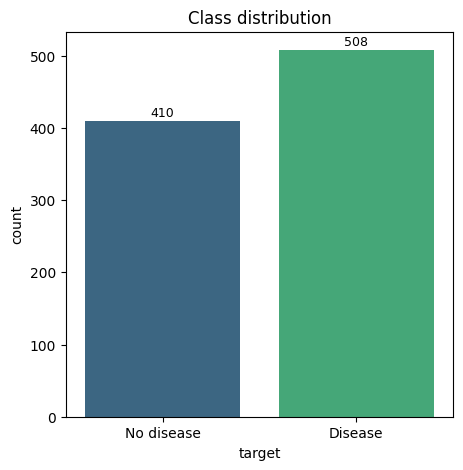

In [25]:
plt.figure(figsize=(5,5))
ax = sns.countplot(x='target', data=df, hue='target', palette='viridis', legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No disease', 'Disease'])
plt.title('Class distribution')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')
plt.show()

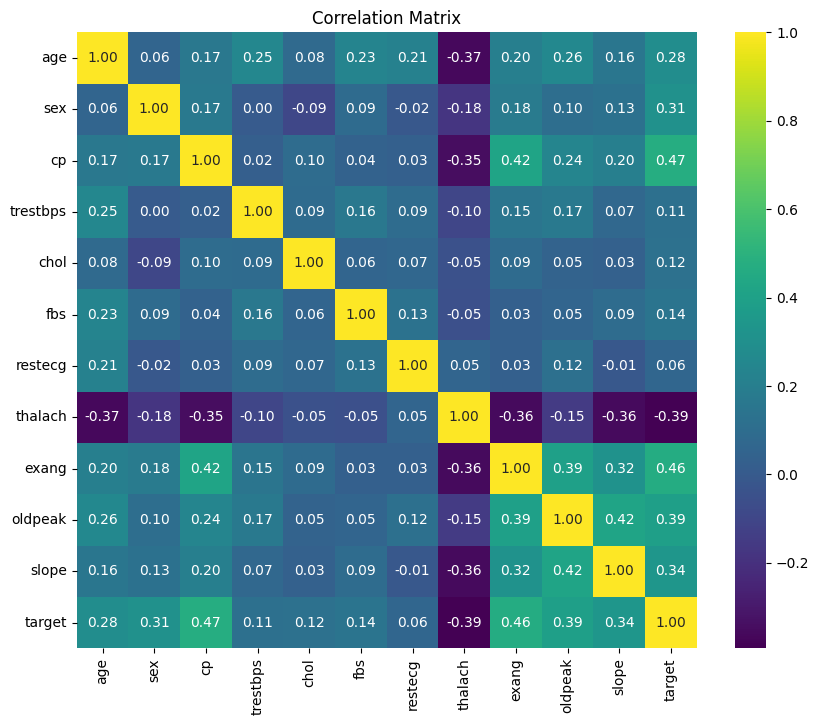

In [26]:
plt.figure(figsize=(10,8))
sns.heatmap(df[features + ['target']].corr(), annot=True, fmt='.2f', cmap='viridis')
plt.title('Correlation Matrix')
plt.show()

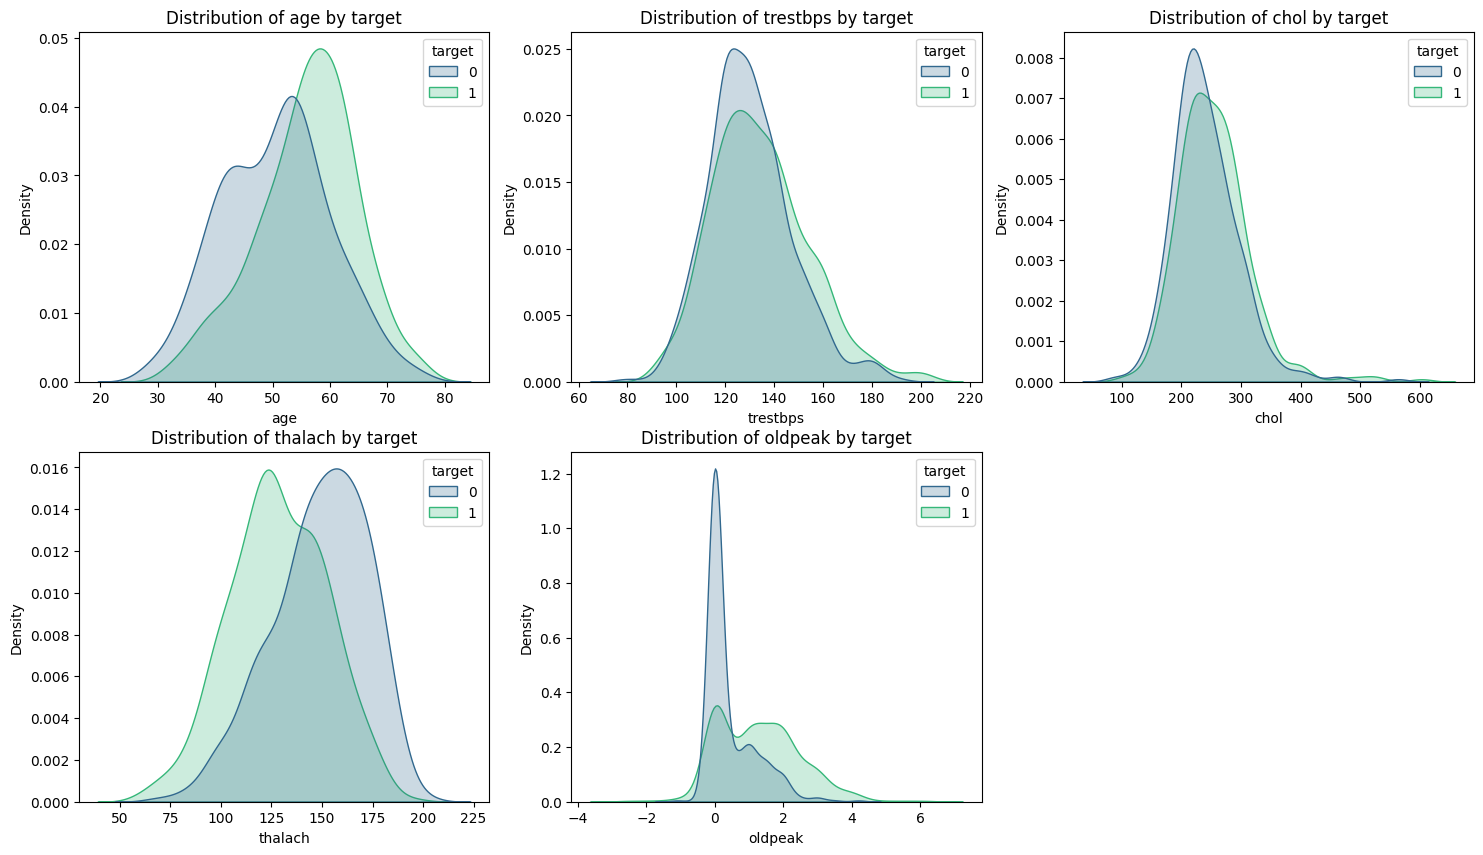

In [27]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18,10))
axes[1,2].axis('off')
for ax, col in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=col, hue='target', common_norm=False, fill=True, palette='viridis', ax=ax)
    ax.set_title('Distribution of ' + col + ' by target')
plt.show()

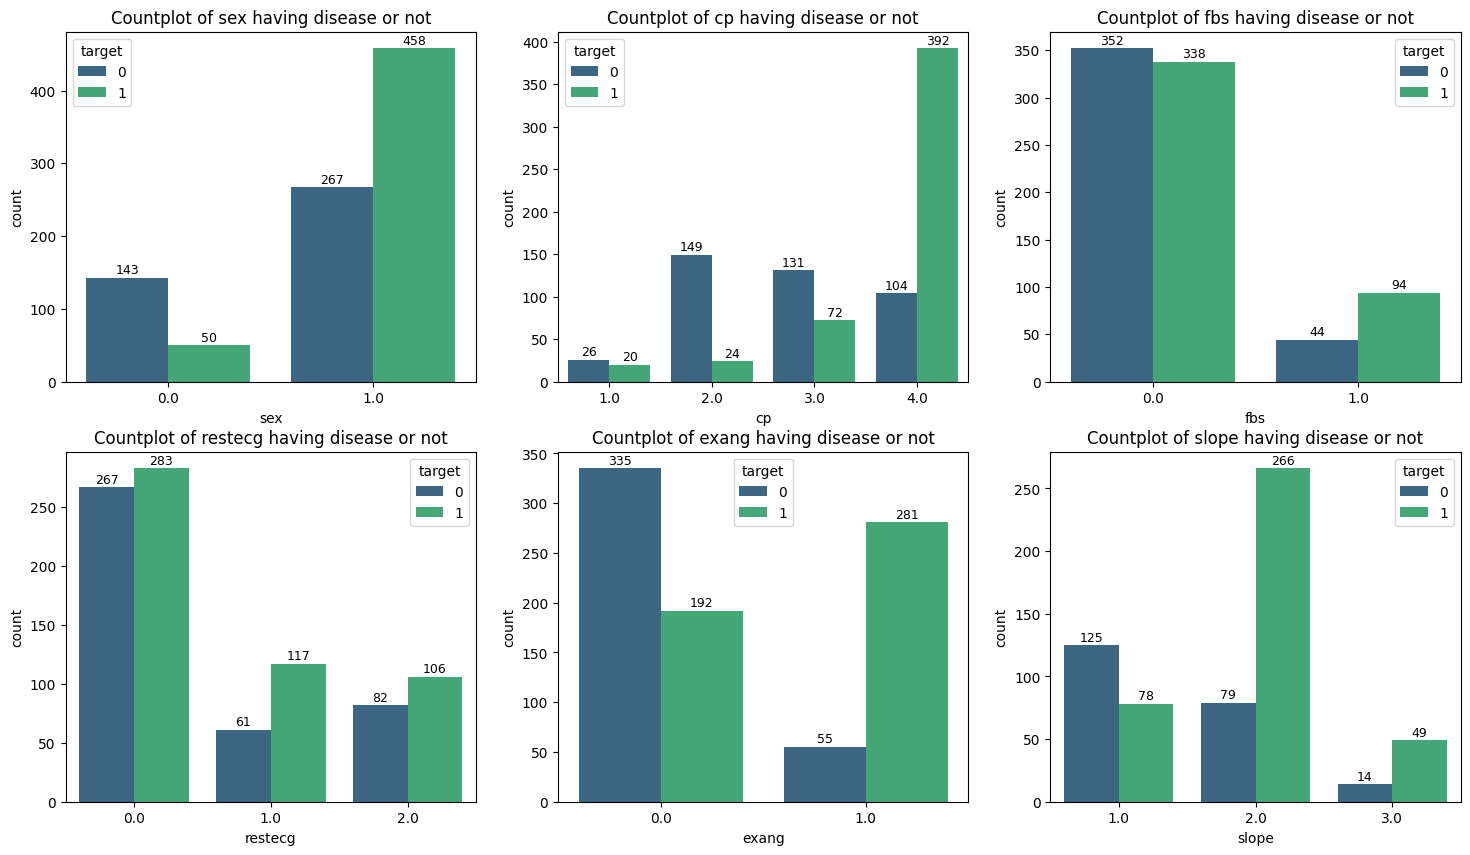

In [28]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18,10))
for ax, col in zip(axes.ravel(), ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']):
    sns.countplot(x=col, data=df, hue='target', palette='viridis', ax=ax)
    ax.set_title('Countplot of ' + col + ' having disease or not')
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='baseline', fontsize=9, color='black', xytext=(0, 3),
                        textcoords='offset points')
plt.show()

What to look for:
- `cp = 4` (asymptomatic chest pain) is mostly sick patients. It sounds strange, but in this data "asymptomatic" means the patient had no typical angina symptoms and was still sent for an angiogram.
- `exang = 1` (pain during exercise), high `oldpeak` and a low `thalach` (max heart rate) all go with disease.
- Men are a large majority and more often sick.

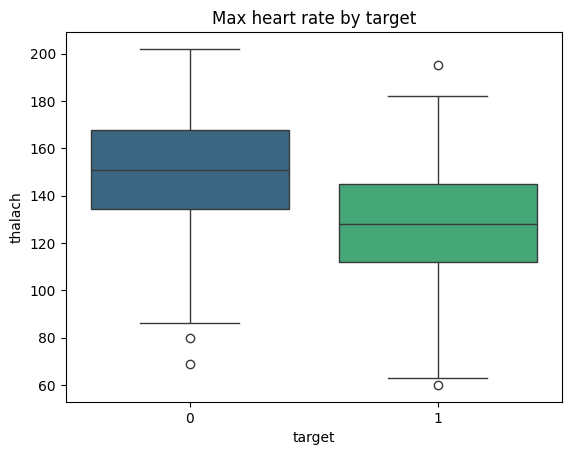

In [29]:
sns.boxplot(data=df, x='target', y='thalach', hue='target', palette='viridis', legend=False)
plt.title('Max heart rate by target')
plt.show()

# Train Test Split

20% of the patients are kept as the test set and only used once at the end. The split is stratified on target and hospital together, so every hospital is in train and test with the same share of sick patients.

All the model choices (which model, hyper parameters, threshold) are made with 5-fold cross validation on the training set. With 900 patients a single validation split is too noisy.

In [30]:
X = df[features]
y = df['target']
strat = df['site'] + '_' + df['target'].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=strat, random_state=42)
site_test = df.loc[X_test.index, 'site']

In [31]:
X_train.shape, X_test.shape

((734, 11), (184, 11))

In [32]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

## Preprocessing pipeline

Everything (filling missing values, scaling, one hot encoding) is inside one sklearn `Pipeline` together with the model. Two reasons:
- no leakage: in cross validation the medians and the scaler are learnt only on the training folds
- the app saves and loads one object, and gives it the raw values the user typed (the same codes as the UCI file), the pipeline does the rest

`cp`, `restecg`, `slope`, `thal` are categories (code 3 is not "more" than code 2), so they are one hot encoded. Logistic regression needs this, for the random forest it does not hurt.

In [33]:
def make_preprocessor():
    num_pipe = Pipeline([('impute', SimpleImputer(strategy = 'median')), ('scale', StandardScaler())])
    cat_pipe = Pipeline([('impute', SimpleImputer(strategy = 'most_frequent')), ('onehot', OneHotEncoder(handle_unknown = 'ignore'))])
    bin_pipe = Pipeline([('impute', SimpleImputer(strategy = 'most_frequent'))])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols),
        ('bin', bin_pipe, bin_cols)
    ])

In [34]:
make_preprocessor().fit_transform(X_train).shape

(734, 18)

## Evaluation function

For a disease screening model the two errors are not equal:
- **False negative** (sick patient told "no disease") -> the patient goes home, this is the dangerous one
- **False positive** (healthy patient told "disease") -> one extra test

So the main numbers are **recall of the disease class** (out of all sick patients, how many the model catches) and the number of false negatives in the confusion matrix, together with precision (how many of the "disease" predictions are right) and ROC AUC (how well the model ranks sick above healthy patients, independent of the threshold).

In [35]:
results = []

def evaluate(name, y_true, y_prob, threshold = 0.5):
    y_pred = (y_prob >= threshold).astype(int)
    print('Accuracy Score :', accuracy_score(y_true, y_pred))
    print('Recall (disease) :', recall_score(y_true, y_pred))
    print('Precision (disease) :', precision_score(y_true, y_pred))
    print('ROC AUC :', roc_auc_score(y_true, y_prob))

    cm = confusion_matrix(y_true, y_pred)
    target_names = ['No disease', 'Disease']
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
    plt.title('Confusion Matrix - ' + name)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

    print(classification_report(y_true, y_pred, target_names=target_names, digits=5))
    results.append({'model': name, 'threshold': threshold, 'accuracy': accuracy_score(y_true, y_pred),
                    'recall': recall_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred),
                    'f1': f1_score(y_true, y_pred), 'roc_auc': roc_auc_score(y_true, y_prob),
                    'false_negatives': int(cm[1, 0])})

# Logistic Regression (baseline)

In [36]:
lr = Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter = 1000))])

In [37]:
# cross validation on the training set
lr_cv = cross_val_score(lr, X_train, y_train, cv = cv, scoring = 'roc_auc')
print('CV ROC AUC :', lr_cv.mean().round(4), '+-', lr_cv.std().round(4))

CV ROC AUC : 0.8749 +- 0.0196


Accuracy Score : 0.8097826086956522
Recall (disease) : 0.8529411764705882
Precision (disease) : 0.8130841121495327
ROC AUC : 0.8749402199904353


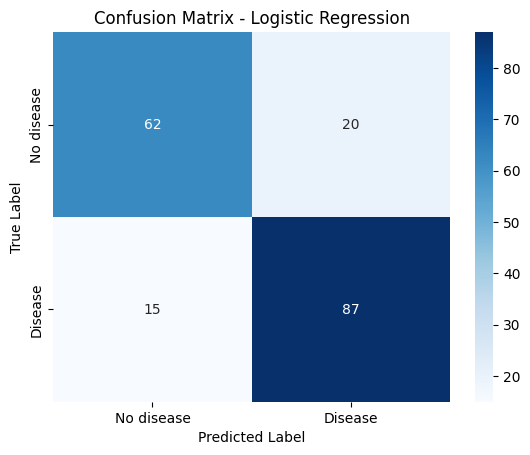

              precision    recall  f1-score   support

  No disease    0.80519   0.75610   0.77987        82
     Disease    0.81308   0.85294   0.83254       102

    accuracy                        0.80978       184
   macro avg    0.80914   0.80452   0.80621       184
weighted avg    0.80957   0.80978   0.80907       184



In [38]:
lr.fit(X_train, y_train)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
evaluate('Logistic Regression', y_test, y_prob_lr)

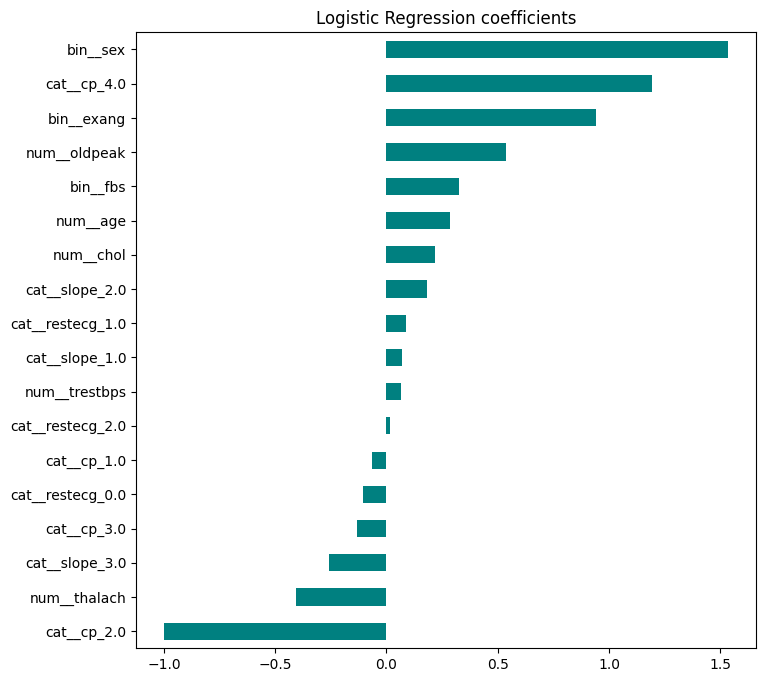

In [39]:
# coefficients of the baseline, positive -> more risk (numeric columns are scaled, so they can be compared)
coef_names = lr.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lr.named_steps['model'].coef_[0], index = coef_names).sort_values()
coefs.plot(kind = 'barh', figsize = (8,8), color = 'teal')
plt.title('Logistic Regression coefficients')
plt.show()

# Random Forest

In [40]:
rf = Pipeline([('prep', make_preprocessor()), ('model', RandomForestClassifier(n_estimators = 300, random_state = 42, n_jobs = -1))])

In [41]:
rf_cv = cross_val_score(rf, X_train, y_train, cv = cv, scoring = 'roc_auc')
print('CV ROC AUC :', rf_cv.mean().round(4), '+-', rf_cv.std().round(4))

CV ROC AUC : 0.8638 +- 0.0388


Accuracy Score : 0.8097826086956522
Recall (disease) : 0.8725490196078431
Precision (disease) : 0.8018018018018018
ROC AUC : 0.866272118603539


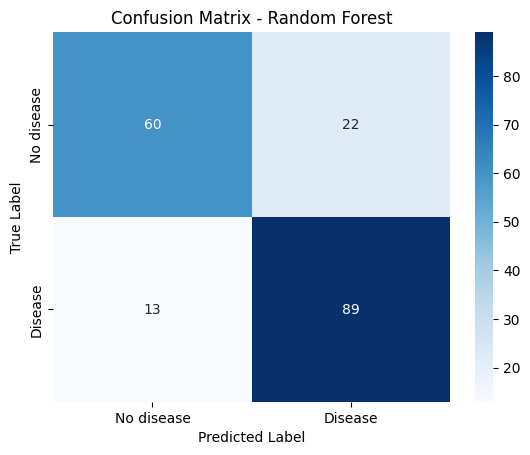

              precision    recall  f1-score   support

  No disease    0.82192   0.73171   0.77419        82
     Disease    0.80180   0.87255   0.83568       102

    accuracy                        0.80978       184
   macro avg    0.81186   0.80213   0.80494       184
weighted avg    0.81077   0.80978   0.80828       184



In [42]:
rf.fit(X_train, y_train)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
evaluate('Random Forest', y_test, y_prob_rf)

## Tuning the Random Forest

The default forest grows every tree until the leaves are pure, which overfits on 700 patients. `RandomizedSearchCV` tries 40 random combinations with 5-fold CV and keeps the best one by ROC AUC. The most important ones are `max_depth`, `min_samples_leaf` (bigger -> smoother probabilities) and `max_features`.

`class_weight = 'balanced'` is also tried, it gives the smaller class more weight in training (here the classes are close to 50/50, so it may not matter).

In [43]:
param_dist = {
    'model__n_estimators': [200, 300, 500, 800],
    'model__max_depth': [3, 4, 5, 6, 8, 10, None],
    'model__min_samples_leaf': [1, 2, 4, 6, 10],
    'model__min_samples_split': [2, 5, 10],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__class_weight': [None, 'balanced']
}

rf_search = RandomizedSearchCV(rf, param_dist, n_iter = 40, scoring = 'roc_auc', cv = cv, random_state = 42, n_jobs = -1, verbose = 1)
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['age',
                                                                                'trestbps',
                                                                                'chol',
                                                                                'thalach',
                                                                                'oldpeak']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='most_...
                                                                     n_jobs=-1,
                                                                     random_state=42))]),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'model__class_weight': [None,
                                                                'balanced'],
                                        'model__max_depth': [3, 4, 5, 6, 8, 10,
                                                             None],
                                        'model__max_features': ['sqrt', 'log2',
                                                                0.5],
                                        'model__min_samples_leaf': [1, 2, 4, 6,
                                                                    10],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [200, 300, 500,
                                                                800]},
                   random_state=42, scoring='roc_auc', verbose=1)

In [44]:
print('Best CV ROC AUC :', round(rf_search.best_score_, 4))
rf_search.best_params_

Best CV ROC AUC : 0.8765


{'model__n_estimators': 300,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 6,
 'model__max_features': 'log2',
 'model__max_depth': 5,
 'model__class_weight': None}

Accuracy Score : 0.7989130434782609
Recall (disease) : 0.8627450980392157
Precision (disease) : 0.7927927927927928
ROC AUC : 0.8745815399330464


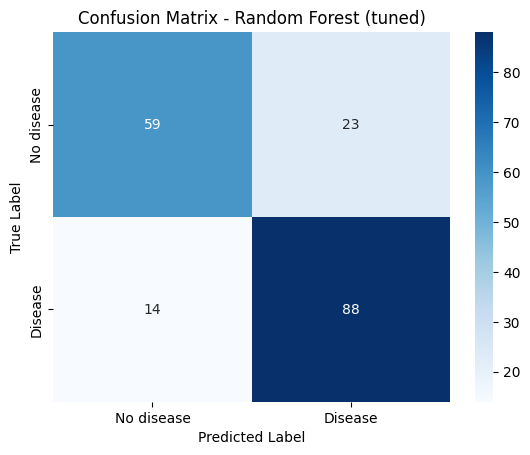

              precision    recall  f1-score   support

  No disease    0.80822   0.71951   0.76129        82
     Disease    0.79279   0.86275   0.82629       102

    accuracy                        0.79891       184
   macro avg    0.80051   0.79113   0.79379       184
weighted avg    0.79967   0.79891   0.79732       184



In [45]:
rf_tuned = rf_search.best_estimator_
y_prob_rf_tuned = rf_tuned.predict_proba(X_test)[:, 1]
evaluate('Random Forest (tuned)', y_test, y_prob_rf_tuned)

# XGBoost

In [46]:
xgb = Pipeline([('prep', make_preprocessor()), ('model', XGBClassifier(eval_metric = 'logloss', random_state = 42, n_jobs = -1))])

xgb_dist = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [2, 3, 4, 5],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5]
}

xgb_search = RandomizedSearchCV(xgb, xgb_dist, n_iter = 40, scoring = 'roc_auc', cv = cv, random_state = 42, n_jobs = -1, verbose = 1)
xgb_search.fit(X_train, y_train)
print('Best CV ROC AUC :', round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best CV ROC AUC : 0.8784


Accuracy Score : 0.8152173913043478
Recall (disease) : 0.8823529411764706
Precision (disease) : 0.8035714285714286
ROC AUC : 0.8845050215208035


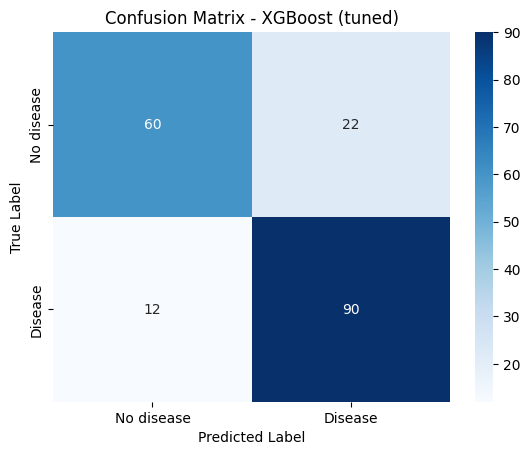

              precision    recall  f1-score   support

  No disease    0.83333   0.73171   0.77922        82
     Disease    0.80357   0.88235   0.84112       102

    accuracy                        0.81522       184
   macro avg    0.81845   0.80703   0.81017       184
weighted avg    0.81683   0.81522   0.81354       184



In [47]:
xgb_tuned = xgb_search.best_estimator_
y_prob_xgb = xgb_tuned.predict_proba(X_test)[:, 1]
evaluate('XGBoost (tuned)', y_test, y_prob_xgb)

# Comparison

In [48]:
pd.DataFrame(results).round(4)

,model,threshold,accuracy,recall,precision,f1,roc_auc,false_negatives
0,Logistic Regression,0.5,0.8098,0.8529,0.8131,0.8325,0.8749,15
1,Random Forest,0.5,0.8098,0.8725,0.8018,0.8357,0.8663,13
2,Random Forest (tuned),0.5,0.7989,0.8627,0.7928,0.8263,0.8746,14
3,XGBoost (tuned),0.5,0.8152,0.8824,0.8036,0.8411,0.8845,12


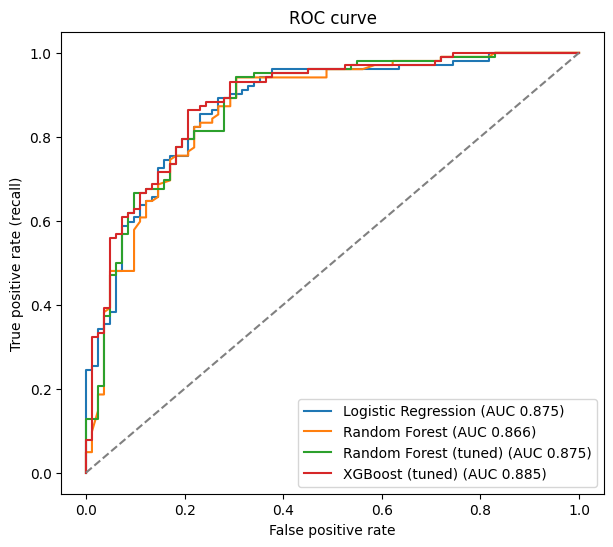

In [49]:
plt.figure(figsize=(7,6))
for name, prob in [('Logistic Regression', y_prob_lr), ('Random Forest', y_prob_rf), ('Random Forest (tuned)', y_prob_rf_tuned), ('XGBoost (tuned)', y_prob_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label = name + ' (AUC ' + str(round(roc_auc_score(y_test, prob), 3)) + ')')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'grey')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve')
plt.legend()
plt.show()

How to read this: on 900 patients the models are usually within 1 - 3 points of each other and the logistic regression baseline is hard to beat by much (this is a small, mostly linear problem). With a test set of ~180 patients one patient is about 0.5% accuracy, so small differences on the test set are noise.

That is why the final model is picked with the **cross validation score on the training set**, not with the test set (picking by the test set would make the test score optimistic).

In [50]:
cv_scores = {
    'Logistic Regression': lr_cv.mean(),
    'Random Forest (tuned)': rf_search.best_score_,
    'XGBoost (tuned)': xgb_search.best_score_
}
candidates = {'Logistic Regression': lr, 'Random Forest (tuned)': rf_tuned, 'XGBoost (tuned)': xgb_tuned}

best_name = max(cv_scores, key = cv_scores.get)
print(pd.Series(cv_scores).round(4))
print('Chosen model :', best_name)

Logistic Regression      0.8749
Random Forest (tuned)    0.8765
XGBoost (tuned)          0.8784
dtype: float64
Chosen model : XGBoost (tuned)


# Calibration

The app shows a probability ("62% risk"), so the probability has to mean something: of all patients the model gives 0.6, about 60% should really be sick. Random forests are known to push probabilities towards the middle, XGBoost can be over confident.

`CalibratedClassifierCV` fits a small sigmoid on top of the model with 5-fold CV (Platt scaling). The Brier score (mean squared error of the probability, lower is better) and the reliability plot show if it helped.

In [51]:
final_model = CalibratedClassifierCV(estimator = clone(candidates[best_name]), method = 'sigmoid', cv = 5)
final_model.fit(X_train, y_train)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

y_prob_best = candidates[best_name].predict_proba(X_test)[:, 1]
print('Brier score before calibration :', round(brier_score_loss(y_test, y_prob_best), 4))
print('Brier score after calibration :', round(brier_score_loss(y_test, y_prob_final), 4))

Brier score before calibration : 0.1332
Brier score after calibration : 0.1353


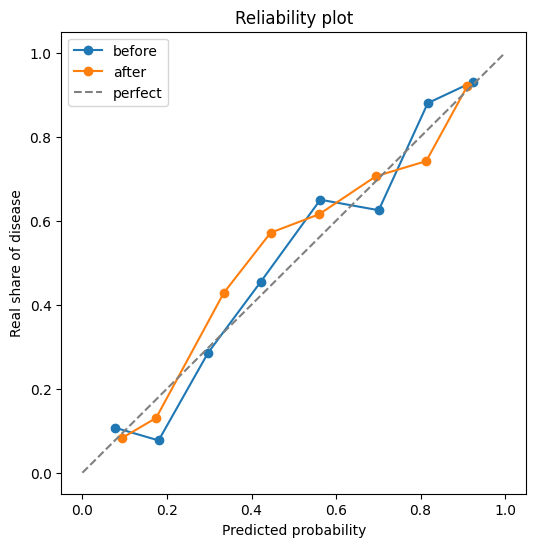

In [52]:
plt.figure(figsize=(6,6))
for name, prob in [('before', y_prob_best), ('after', y_prob_final)]:
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins = 8)
    plt.plot(mean_pred, frac_pos, marker = 'o', label = name)
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'grey', label = 'perfect')
plt.xlabel('Predicted probability')
plt.ylabel('Real share of disease')
plt.title('Reliability plot')
plt.legend()
plt.show()

# Decision threshold

With threshold 0.5 the model treats both errors the same. For screening, missing a sick patient is worse, so the threshold is lowered until the recall is at least `target_recall`. The cost is more false positives.

The threshold is chosen on **out of fold** probabilities of the training set (every training patient gets a prediction from a model that did not see them), so the test set is still untouched.

In [53]:
target_recall = 0.90

In [54]:
oof_prob = cross_val_predict(final_model, X_train, y_train, cv = cv, method = 'predict_proba')[:, 1]

rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (oof_prob >= t).astype(int)
    rows.append({'threshold': round(t, 2), 'recall': recall_score(y_train, pred), 'precision': precision_score(y_train, pred),
                 'accuracy': accuracy_score(y_train, pred)})
thr_table = pd.DataFrame(rows)
thr_table.round(4)

,threshold,recall,precision,accuracy
0,0.10,0.9951,0.6039,0.6362
1,0.15,0.9852,0.6547,0.7044
2,0.20,0.9655,0.6938,0.7452
3,0.25,0.9557,0.7293,0.7793
4,0.30,0.9236,0.7426,0.7807
5,0.35,0.9089,0.7561,0.7875
6,0.40,0.8892,0.7814,0.8011
7,0.45,0.8596,0.7932,0.7984
8,0.50,0.8325,0.8086,0.7984
9,0.55,0.8030,0.8191,0.7929


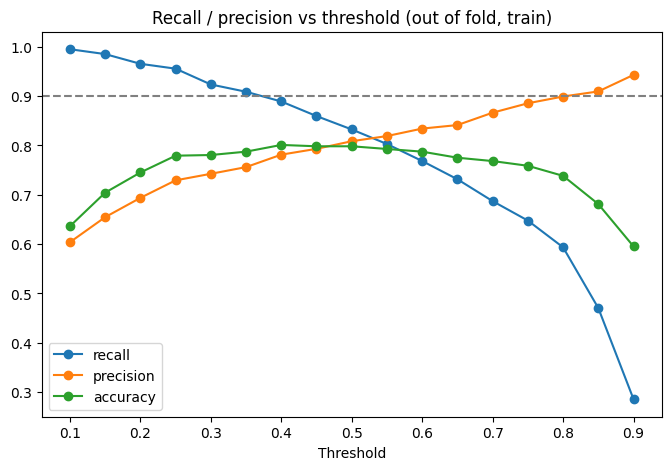

In [55]:
plt.figure(figsize=(8,5))
plt.plot(thr_table['threshold'], thr_table['recall'], marker = 'o', label = 'recall')
plt.plot(thr_table['threshold'], thr_table['precision'], marker = 'o', label = 'precision')
plt.plot(thr_table['threshold'], thr_table['accuracy'], marker = 'o', label = 'accuracy')
plt.axhline(target_recall, linestyle = '--', color = 'grey')
plt.xlabel('Threshold')
plt.title('Recall / precision vs threshold (out of fold, train)')
plt.legend()
plt.show()

In [56]:
# the highest threshold that still gives the target recall
ok = thr_table[thr_table['recall'] >= target_recall]
threshold = float(ok['threshold'].max()) if len(ok) > 0 else 0.5
print('Chosen threshold :', threshold)

Chosen threshold : 0.35


# Final evaluation on the test set

Accuracy Score : 0.8097826086956522
Recall (disease) : 0.8725490196078431
Precision (disease) : 0.8018018018018018
ROC AUC : 0.8799617407938785


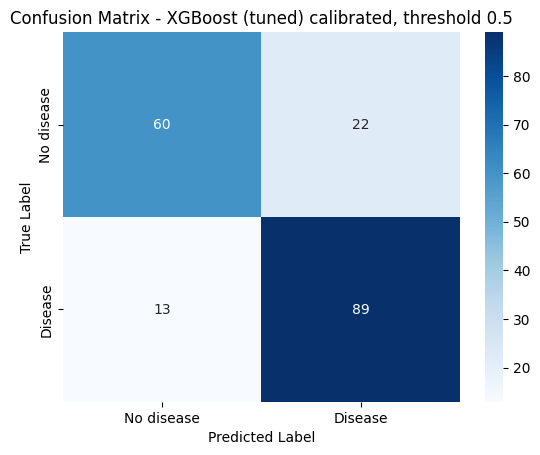

              precision    recall  f1-score   support

  No disease    0.82192   0.73171   0.77419        82
     Disease    0.80180   0.87255   0.83568       102

    accuracy                        0.80978       184
   macro avg    0.81186   0.80213   0.80494       184
weighted avg    0.81077   0.80978   0.80828       184



In [57]:
evaluate(best_name + ' calibrated, threshold 0.5', y_test, y_prob_final, threshold = 0.5)

Accuracy Score : 0.8097826086956522
Recall (disease) : 0.9313725490196079
Precision (disease) : 0.7723577235772358
ROC AUC : 0.8799617407938785


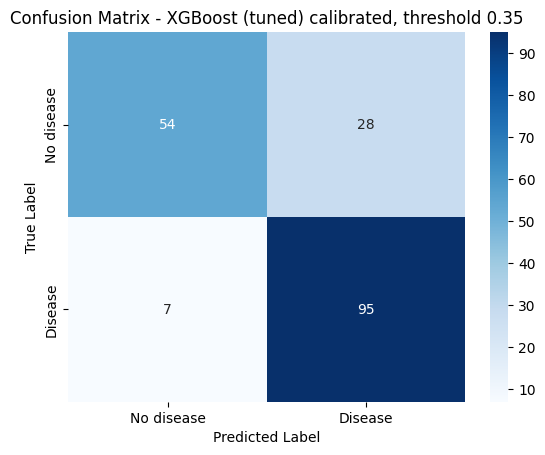

              precision    recall  f1-score   support

  No disease    0.88525   0.65854   0.75524        82
     Disease    0.77236   0.93137   0.84444       102

    accuracy                        0.80978       184
   macro avg    0.82880   0.79495   0.79984       184
weighted avg    0.82267   0.80978   0.80469       184



In [58]:
evaluate(best_name + ' calibrated, threshold ' + str(threshold), y_test, y_prob_final, threshold = threshold)

In [59]:
pd.DataFrame(results).round(4)

,model,threshold,accuracy,recall,precision,f1,roc_auc,false_negatives
0,Logistic Regression,0.50,0.8098,0.8529,0.8131,0.8325,0.8749,15
1,Random Forest,0.50,0.8098,0.8725,0.8018,0.8357,0.8663,13
2,Random Forest (tuned),0.50,0.7989,0.8627,0.7928,0.8263,0.8746,14
3,XGBoost (tuned),0.50,0.8152,0.8824,0.8036,0.8411,0.8845,12
4,"XGBoost (tuned) calibrated, threshold 0.5",0.50,0.8098,0.8725,0.8018,0.8357,0.8800,13
5,"XGBoost (tuned) calibrated, threshold 0.35",0.35,0.8098,0.9314,0.7724,0.8444,0.8800,7


In [60]:
# results per hospital, to check the model is not only good on one of them
y_pred_final = (y_prob_final >= threshold).astype(int)
site_rows = []
for site in site_test.unique():
    mask = (site_test == site).values
    row = {'site': site, 'patients': int(mask.sum()), 'disease share': y_test[mask].mean(),
           'accuracy': accuracy_score(y_test[mask], y_pred_final[mask]), 'recall': recall_score(y_test[mask], y_pred_final[mask], zero_division = 0)}
    row['roc_auc'] = roc_auc_score(y_test[mask], y_prob_final[mask]) if y_test[mask].nunique() == 2 else np.nan
    site_rows.append(row)
pd.DataFrame(site_rows).round(3)

,site,patients,disease share,accuracy,recall,roc_auc
0,cleveland,61,0.459,0.836,1.000,0.942
1,switzerland,25,0.920,0.920,0.957,0.783
2,hungary,58,0.362,0.776,0.810,0.856
3,va,40,0.750,0.750,0.933,0.733


Switzerland is almost only sick patients, so its accuracy is mostly "say disease" and its AUC is based on a handful of healthy patients. Cleveland and Hungary are the most informative rows.

# Feature importance

cp          0.0854
oldpeak     0.0315
sex         0.0182
chol        0.0121
exang       0.0111
thalach     0.0074
age         0.0051
slope       0.0007
trestbps    0.0002
fbs         0.0000
restecg    -0.0002
dtype: float64


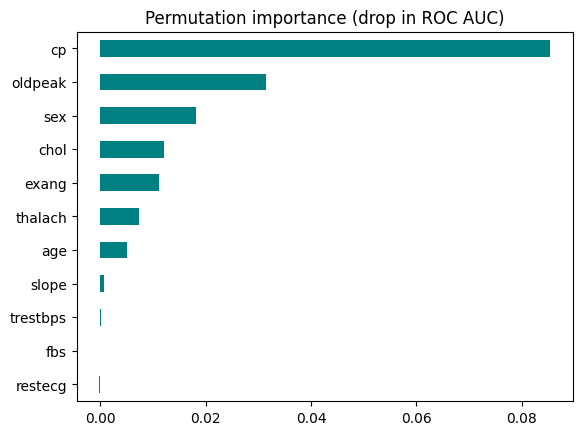

In [61]:
# permutation importance: how much the test ROC AUC drops when one column is shuffled
# done on the raw columns, so it is the same names the user types in the app
perm = permutation_importance(final_model, X_test, y_test, scoring = 'roc_auc', n_repeats = 20, random_state = 42, n_jobs = -1)
imp = pd.Series(perm.importances_mean, index = features).sort_values(ascending = False)
print(imp.round(4))
imp.sort_values().plot(kind = 'barh', color = 'teal')
plt.title('Permutation importance (drop in ROC AUC)')
plt.show()

# Save the model

In [62]:
joblib.dump(final_model, save_dir + '/tabular_model.joblib', compress = 3)

final_row = [r for r in results if r['threshold'] == threshold and r['model'].startswith(best_name)][-1]

# the app reads this file: which inputs to show, their ranges, the threshold and the scores
config = {
    'model_name': best_name + ' (calibrated)',
    'keep_ca_thal': keep_ca_thal,
    'features': features,
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'bin_cols': bin_cols,
    'ranges': {c: [float(X_train[c].min()), float(X_train[c].max()), float(X_train[c].median())] for c in num_cols},
    'threshold': threshold,
    'target_recall': target_recall,
    'test_metrics': {k: float(v) for k, v in final_row.items() if k not in ['model', 'threshold']},
    'cv_roc_auc': {k: float(v) for k, v in cv_scores.items()},
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'sklearn': sklearn.__version__
}
json.dump(config, open(save_dir + '/tabular_config.json', 'w'), indent = 2)
os.listdir(save_dir)

['tabular_model.joblib', 'tabular_config.json']

# Try it

In [63]:
# one patient, the same raw codes as the UCI file, missing values can be left as None
patient = {'age': 58, 'sex': 1, 'cp': 4, 'trestbps': 140, 'chol': 260, 'fbs': 0, 'restecg': 2,
           'thalach': 120, 'exang': 1, 'oldpeak': 2.0, 'slope': 2, 'ca': 1, 'thal': 7}
patient_df = pd.DataFrame([{c: patient.get(c) for c in features}], dtype = float)

prob = final_model.predict_proba(patient_df)[0, 1]
print('Risk :', round(prob, 3), '| Prediction :', 'Disease' if prob >= threshold else 'No disease')

Risk : 0.925 | Prediction : Disease


Part 1 is done, `tabular_model.joblib` and `tabular_config.json` are in the Drive folder `heart_disease`. Next: `HeartDisease_Part2_ChestXray.ipynb` in a GPU session.

Notes for the interview:
- Logistic regression is the baseline for classification, linear regression is for continuous targets.
- The test set is used once. Model choice, tuning and the threshold all come from cross validation on the training set.
- The threshold is set for recall because a missed sick patient costs more than an extra test.
- The hospital is not a feature, the share of sick patients is 46% in Cleveland and 94% in Switzerland, so the model could cheat with it.
- 900 patients from the 1980s is small and old. Real use would need validation on new patients from the hospital where it will run.